In [2]:
# import liberaries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
# loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()
# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else (x))

In [3]:
df = df[df['job_title_short'] == "Data Scientist"].copy()

In [4]:
# Count True and False values
work_from_home = df['job_work_from_home'].value_counts()
work_from_home

job_work_from_home
False    157751
True      14535
Name: count, dtype: int64

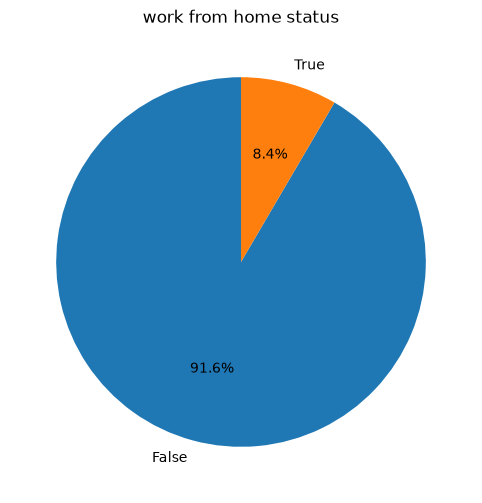

In [5]:
# Plotting the pie chart
plt.figure(figsize=(6,6))
work_from_home.plot( kind = 'pie',
startangle = 90, 
autopct = '%1.1f%%')
plt.title('work from home status')
plt.ylabel('')
plt.show()

In [6]:
df[['job_work_from_home', 'job_no_degree_mention', 'job_health_insurance']]

,job_work_from_home,job_no_degree_mention,job_health_insurance
9,True,False,False
17,False,False,True
19,False,False,False
20,False,False,False
21,False,False,False
...,...,...,...
785689,False,False,False
785690,False,False,False
785692,False,False,True
785697,False,False,False


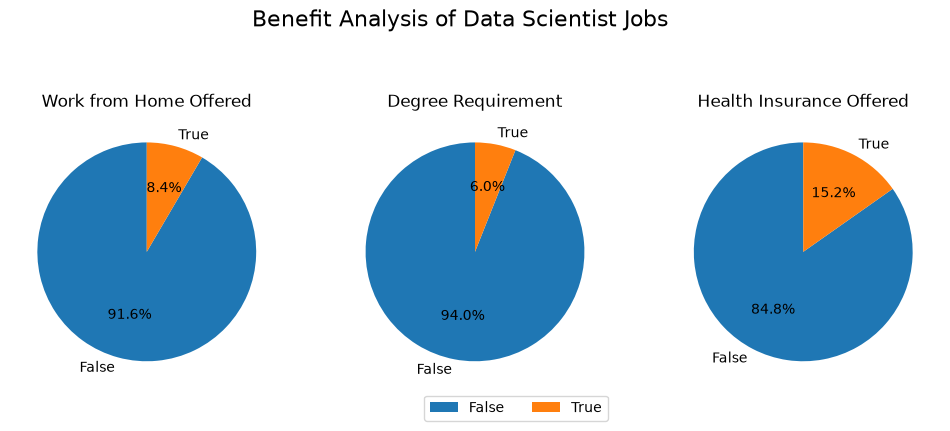

In [8]:
# rewrite the above with a for loop instead of doing one by one 
fig , ax = plt.subplots(1, 3)
fig.set_size_inches((12, 5))
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'}
for i , (column , title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(), labels = ['False' , 'True' ],startangle = 90 , autopct ='%1.1f%%' )
    ax[i].set_title(title)
plt.suptitle('Benefit Analysis of Data Scientist Jobs', fontsize=16)
plt.legend(loc='upper center', bbox_to_anchor=(-0.55, 0), ncol=2)
plt.show()